# 03 — Modèles statistiques : naïf saisonnier, Holt-Winters, SARIMA

Trois modèles, du plus bête au plus élaboré. Deux façons de les regarder :

1. une **prévision longue** (une saison entière d'un coup) — pour voir la forme ;
2. une **prévision courte à 1 et 4 semaines**, refaite chaque semaine — c'est l'usage
   réel d'un système de veille, et c'est là que se joue la comparaison.

Le backtest complet, sur toutes les saisons récentes, est au notebook 06.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import preprocessing, models, plotting
s = preprocessing.serie_hebdo(3, 'PAY').dropna()
coupe = '2023-08-01'
train, test = s.loc[:coupe], s.loc[coupe:]
print(len(train), 'semaines train /', len(test), 'test')

1722 semaines train / 159 test


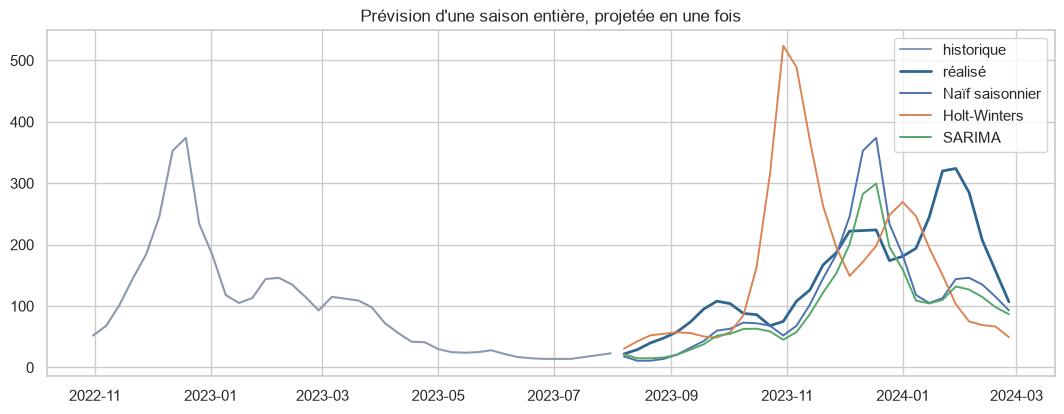

,Naïf saisonnier,Holt-Winters,SARIMA
MAE (30 sem.),56.07,100.65,57.67


In [2]:
# 1) Prévision longue : une saison (30 semaines) projetée d'un seul coup.
horizon_long = 30
resultats = {}
for nom, ctor in [("Naïf saisonnier", models.SeasonalNaive),
                  ("Holt-Winters", models.HoltWinters),
                  ("SARIMA", models.Sarima)]:
    f = ctor().fit(train).forecast(horizon_long)
    resultats[nom] = f

cible = test.iloc[:horizon_long]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(train.index[-40:], train.iloc[-40:], color=plotting.GRIS, label="historique")
ax.plot(cible.index, cible.values, color=plotting.BLEU, lw=2, label="réalisé")
for nom, f in resultats.items():
    ax.plot(f.index, f.values, lw=1.4, label=nom)
ax.set_title("Prévision d'une saison entière, projetée en une fois"); ax.legend()
plotting.save(fig, "03_prevision_longue")
plt.show()
pd.DataFrame({n: (f.reindex(cible.index) - cible).abs().mean() for n, f in resultats.items()},
             index=["MAE (30 sem.)"]).round(2)

En projection longue, aucun des trois n'est vraiment bon : ils donnent la *forme*
saisonnière mais ratent l'amplitude et le calage du pic. C'est attendu — personne ne
demande une prévision à 30 semaines. Holt-Winters est le plus faible : les pics de grippe
sont trop variables en amplitude d'une année sur l'autre pour une saisonnalité additive, et
trop proches de zéro l'été pour passer en multiplicatif sans instabilité.

In [3]:
# 2) Prévision courte : à chaque semaine du test, on prévoit t+1 et t+4.
def rolling_court(ctor, s, debut, horizons=(1, 4), refit_every=13):
    idx = s.index; i0 = idx.get_indexer([pd.Timestamp(debut)], method="bfill")[0]
    m = None; rows = []
    for k, i in enumerate(range(i0, len(s) - max(horizons))):
        hist = s.iloc[:i + 1]
        if m is None or k % refit_every == 0:
            m = ctor().fit(hist)
        else:
            m.update(hist)
        f = m.forecast(max(horizons))
        for h in horizons:
            rows.append({"h": h, "reel": s.iloc[i + h], "prev": float(f.iloc[h - 1])})
    d = pd.DataFrame(rows)
    return d.groupby("h").apply(lambda g: (g["reel"] - g["prev"]).abs().mean())

court = pd.DataFrame({
    nom: rolling_court(ctor, s, coupe)
    for nom, ctor in [("Naïf saisonnier", models.SeasonalNaive),
                      ("Holt-Winters", models.HoltWinters),
                      ("SARIMA", models.Sarima)]
})
court.index = [f"+{h} sem." for h in court.index]
court.round(2)

,Naïf saisonnier,Holt-Winters,SARIMA
+1 sem.,43.35,26.65,15.23
+4 sem.,43.09,101.42,39.69


En prévision courte, l'ordre s'inverse : **SARIMA passe nettement devant** — MAE ~15 à 1 semaine contre ~43 pour le naïf saisonnier, et il garde l'avantage à 4 semaines. Holt-Winters est carrément instable sur cette série : selon la fenêtre d'apprentissage, sa composante de tendance s'emballe et la prévision peut plus que doubler la valeur réelle. Je ne le retiens pas. Reste SARIMA contre le naïf saisonnier — le notebook 06 tranche sur toutes les saisons.

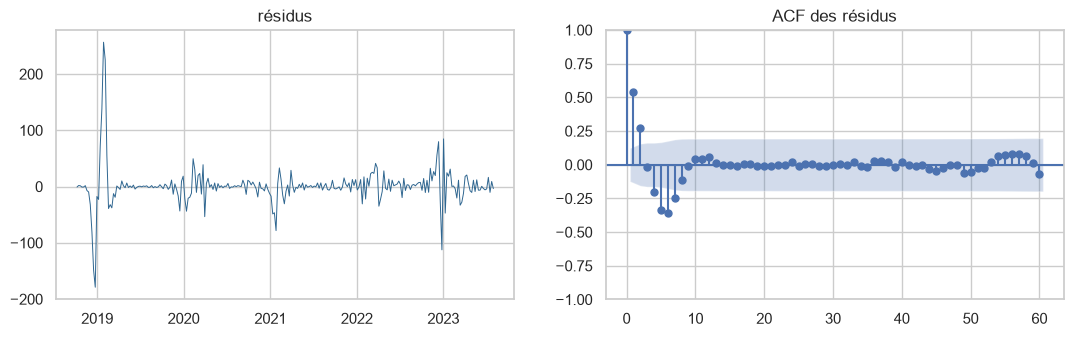

,lb_stat,lb_pvalue
4,104.7123,0.0
12,187.3341,0.0
52,192.1931,0.0


In [4]:
# Diagnostic des résidus SARIMA (in-sample, sur le train).
m = models.Sarima().fit(train)
res = m.res_.resid[60:]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(res.index, res.values, lw=0.7, color=plotting.BLEU); axes[0].set_title("résidus")
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(res, lags=60, ax=axes[1]); axes[1].set_title("ACF des résidus")
plotting.save(fig, "03_residus_sarima")
plt.show()
from statsmodels.stats.diagnostic import acorr_ljungbox
acorr_ljungbox(res, lags=[4, 12, 52], return_df=True).round(4)

Les résidus n'ont pas de saisonnalité résiduelle visible, mais Ljung-Box reste significatif :
il subsiste de l'autocorrélation à court terme que ce SARIMA simple ne capture pas
entièrement. On pourrait pousser la sélection d'ordres, ajouter des régresseurs (météo,
vacances) ou passer à un modèle ML — c'est l'objet des notebooks suivants. En l'état,
SARIMA reste le meilleur des trois pour l'horizon qui nous intéresse.